# 📈 Avaliação Final no Test Set e Explicabilidade do Modelo

Neste notebook, avaliamos o desempenho do melhor modelo (guardado na Fase 4) no conjunto de **Teste (15%)**, totalmente virgem. Geramos a Matriz de Confusão, métricas completas de classificação (Precision, Recall, F1-Score) e analisamos a importância relativa das variáveis.

In [1]:
import sys
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('../src')
from features import prepare_datasets
from models import split_dataset
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, roc_curve

# 1. Carregar dataset limpo e preparar X, y
df_clean = pd.read_csv('../data/processed/ransom_cleaned.csv')
X, y, label_encoder = prepare_datasets(df_clean, target_col='Class')

# 2. Obter a mesma divisão de dados (para isolar os 15% de teste)
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(X, y)

# 3. Carregar o modelo treinado na Fase 4
model_path = '../models/xgboost_ransomware_model.pkl'
if not os.path.exists(model_path):
    model_path = '../models/randomforest_ransomware_model.pkl'

model = joblib.load(model_path)
print(f"✅ Modelo carregado com sucesso a partir de '{model_path}'")

🔹 Conjunto de Treino (70%): 15226 amostras
🔹 Conjunto de Validação (15%): 3263 amostras
🔹 Conjunto de Teste (15%): 3263 amostras
✅ Modelo carregado com sucesso a partir de '../models/xgboost_ransomware_model.pkl'


## 1. Desempenho no Conjunto de Teste (15%)

=== RELATÓRIO DE CLASSIFICAÇÃO (TEST SET) ===
              precision    recall  f1-score   support

      Benign       1.00      0.99      0.99      1632
     Malware       0.99      1.00      0.99      1631

    accuracy                           0.99      3263
   macro avg       0.99      0.99      0.99      3263
weighted avg       0.99      0.99      0.99      3263

ROC-AUC Score: 0.9993


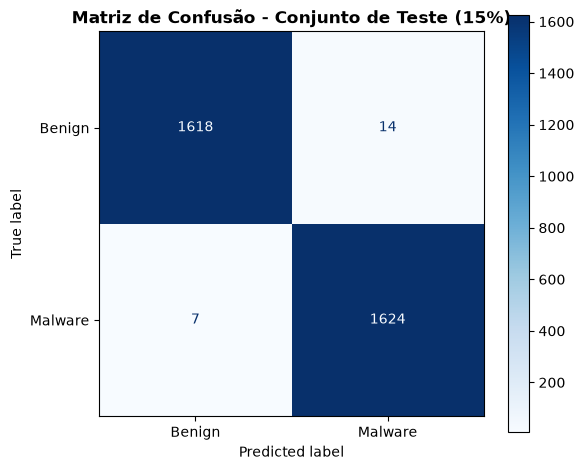

In [2]:
# Previsões no Test Set
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

print("=== RELATÓRIO DE CLASSIFICAÇÃO (TEST SET) ===")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

if y_proba is not None:
    auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}")

# Visualizar Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=label_encoder.classes_, 
    cmap='Blues', 
    ax=ax
)
plt.title('Matriz de Confusão - Conjunto de Teste (15%)', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

## 2. Importância das Features (Top 15)
Análise dos atributos do executável e comportamentos que mais impactaram as decisões do modelo.

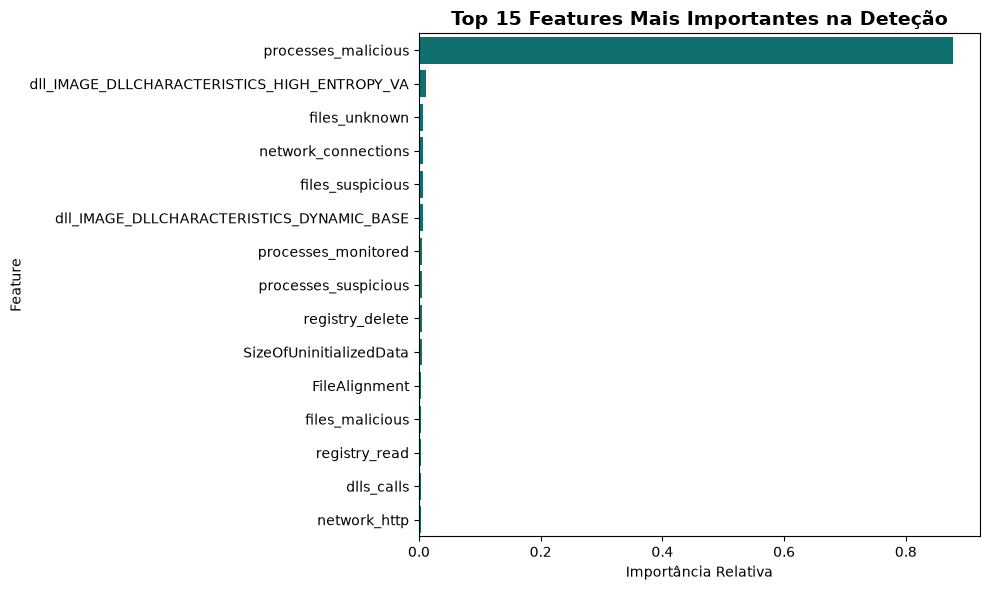

In [ ]:
# Extrair importância das features
if hasattr(model, 'feature_importances_'):
    importances = pd.Series(model.feature_importances_, index=X_test.columns)
    top_15 = importances.nlargest(15)

    plt.figure(figsize=(10, 6))
    # Usamos color='teal' para cor única ou palette='crest' para gradiente
    sns.barplot(x=top_15.values, y=top_15.index, color='teal')
    plt.title('Top 15 Features Mais Importantes na Detecção', fontsize=14, fontweight='bold')
    plt.xlabel('Importância Relativa')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()